# Module 1 - the loader: three ways in, one table out

The loader **imports**; it does not compute crude rates. It reads data that are already processed - crude rates,
or the deaths and exposure that give them - and returns **one table with both sexes**:
`sex | age | Dx | Ex | mx_raw | source`, with a quality report per sex in `df.attrs["qc"]`.

| | Disposition of the files | Function |
|---|---|---|
| **C** (recommended) | one file of elementary data: age, sex, year, deaths, exposure | `load_data(file)` |
| **A** | a file of rates (or deaths) and a file of exposure, sexes in columns | `load_separate(deaths=, exposure=, rates=)` |
| **B** | one file per sex | `load_by_sex(female=, male=)` |

Run from `notebooks/`; terminal equivalent: `python -m pytest tests -v`.

In [1]:
import sys, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "tests")]

import synthetic as S
from src import loader as L

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
BLUE, GREEN, INK, INK_SOFT, GRID = "#1B6CA8", "#3EB553", "#12283D", "#5A6B7C", "#E4E9EE"
COLS = ["sex", "age", "Dx", "Ex", "mx_raw"]

## 1. Synthetic data with a known law, written for every option

In [2]:
truth = {(sex, yr): S.make_sex_table(sex, yr) for sex in ("Female", "Male") for yr in (2020, 2021)}
files = S.write_sample_data(ROOT / "sample_data")          # also handy for the Streamlit uploader
print({k: v.name for k, v in files.items()})
print(files["elementary"].read_text().splitlines()[:3])

{'elementary': 'synthetic_elementary_2020_2021.csv', 'deaths': 'synthetic_Deaths_1x1.txt', 'exposure': 'synthetic_Exposures_1x1.txt', 'rates': 'synthetic_Mx_1x1.txt', 'insee_deaths': 'synthetic_T74BIS_style.csv', 'eurostat_deaths': 'synthetic_demo_magec_style.tsv', 'female_csv': 'synthetic_female_2020.csv', 'male_csv': 'synthetic_male_2020.csv'}
['Year,Sex,Age,Deaths,Exposure', '2020,Female,0,2802,650000.00', '2020,Female,1,1322,621398.36']


## 2. Option C - one file of elementary data

One row per (year, sex, age). The loader picks the year and the sex(es), checks the data and computes `mx_raw = Dx / Ex`.
A file may hold several years, and segments (a region, a geography): the one to keep is chosen, never guessed.

In [3]:
c = L.load_data(files["elementary"], year=2020)            # sex='both' by default
print(c.shape, c.attrs["view"], c.attrs["year"], c.attrs["sexes"])
display(c.groupby("sex").head(2))
display(L.qc_summary(c))

try:
    L.load_data(files["elementary"])                       # two years in the file: say which
except L.AmbiguousSelectionError as e:
    print("refused:", e, "| options =", e.options)

(202, 6) period 2020 ['Female', 'Male']


,sex,age,Dx,Ex,mx_raw,source
0,Female,0,"2,802","650,000",0.00431077,synthetic_elementary_2020_2021.csv
1,Female,1,"1,322","621,398",0.00212746,synthetic_elementary_2020_2021.csv
101,Male,0,"2,965","630,000",0.00470635,synthetic_elementary_2020_2021.csv
102,Male,1,"1,611","602,278",0.00267484,synthetic_elementary_2020_2021.csv


,Contrôle,Female,Male
0,Plage d'âge,0 - 100,0 - 100
1,Nombre de lignes,101,101
2,Nb Dx = 0,0,0
3,Valeurs manquantes (exclues),0,0
4,Décès totaux (somme des Dx),"52,978","100,363"


refused: synthetic_elementary_2020_2021.csv contient 2 années (2020-2021) : précisez `year`. | options = [2020, 2021]


## 3. Option A - rates (or deaths) and exposure, sexes in columns

In [4]:
a = L.load_separate(deaths=files["deaths"], exposure=files["exposure"], year=2020)
pd.testing.assert_frame_equal(a[COLS], c[COLS], check_exact=False, rtol=1e-12)
print("A == C:", a.shape)

# rates + exposure: the deaths are REBUILT (Dx = mx * Ex) - rates alone cannot give them back exactly
r = L.load_separate(rates=files["rates"], exposure=files["exposure"], year=2020)
print([n.message for n in r.attrs["notes"] if n.check == "dx_reconstructed"])
print("max |Dx rebuilt - Dx|:", float((r["Dx"].values - c["Dx"].values).__abs__().max()))

A == C: (202, 6)
["Dx reconstruit = mx x Ex (valeur non entière, au pas d'arrondi de mx près) ; mx_raw reste exactement le mx fourni."]
max |Dx rebuilt - Dx|: 0.2856882799999312


## 4. Option B - one file per sex

In [5]:
b = L.load_by_sex(female=files["female_csv"], male=files["male_csv"])
pd.testing.assert_frame_equal(b[COLS], c[COLS], check_exact=False, rtol=1e-12)
print("B == C:", b.shape)

# the sex button: both, or one
for choice in ("both", "Female", "Male"):
    one = L.load_data(files["elementary"], year=2020, sex=choice)
    print(f"{choice:7s}", one.shape, one.attrs["sexes"])

B == C: (202, 6)
both    (202, 6) ['Female', 'Male']
Female  (101, 6) ['Female']


Male   

 (101, 6) ['Male']


## 5. Other sources: INSEE, Eurostat, Excel tables

The INSEE fixture follows the layout of the real `T74BIS.csv` (`CHAMP2;ANNEE_1975_2024;SEXE;AGE2_REVOLU;NBDEC`:
sexes F / H / E, a `TOT` line, two geographies, and a last age `100` meaning *100 and over*); the Eurostat one follows its
bulk TSV (`unit,sex,age,geo\TIME_PERIOD`, one column per year, `value flag` cells, `:` for missing).

In [6]:
info = L.inspect_file(files["insee_deaths"])
print(info.origin, "| years", info.years, "| sexes", info.sexes, "| segments", info.segments)

# the geography is chosen with where=; the open last age is left out by name
insee = L.load_separate(deaths=L.Source(files["insee_deaths"], where={"CHAMP2": "FM"}),
                        exposure=files["exposure"], year=2020)
print("INSEE:", insee.groupby("sex")["age"].max().to_dict(), [n.message for n in insee.attrs["notes"] if n.check == "non_single_ages"])

euro = L.load_separate(deaths=L.Source(files["eurostat_deaths"], where={"geo": "FR"}),
                       exposure=files["exposure"], year=2020)
print("Eurostat:", euro.groupby("sex")["age"].max().to_dict(), "| origin", L.inspect_file(files["eurostat_deaths"]).origin)

INSEE

 | years [2020, 2021] | sexes ['Female', 'Male'] | segments {'CHAMP2': ['FM', 'FR']}


INSEE: {'Female': 99, 'Male': 99} ["4 ligne(s) hors âge individuel exclue(s) (groupe ouvert, total, ...) : 'TOT' x3, '100+'", "1 ligne(s) hors âge individuel exclue(s) (groupe ouvert, total, ...) : '110+'"]


Eurostat: {'Female': 99, 'Male': 99} | origin Eurostat


In [7]:
# an Excel table the way national offices give it: title lines, years as columns, French age labels
by_year = S.hmd_tables((2020, 2021))
tmp = Path(tempfile.mkdtemp())
d = S.write_wide_years_xlsx(tmp / "deces_femmes.xlsx", "Dx", by_year, "Female")
e = S.write_wide_years_xlsx(tmp / "expo_femmes.xlsx", "Ex", by_year, "Female")
print(pd.read_excel(d, header=None).head(5).to_string())
x = L.load_separate(deaths=d, exposure=e, sex="Female", year=2021)     # sheet names no sex: attributed to the one asked
print(x.shape, "ages", x["age"].min(), "-", x["age"].max())

                                 0     1     2
0  Table synthétique - Dx - Female   NaN   NaN
1      Source : générateur de test   NaN   NaN
2                              Âge 2,020 2,021
3                             0 an 2,802 2,772
4                            1 ans 1,322 1,270
(100, 6) ages 0 - 99


### Population at 1 January -> exposure

Official population series give the population at 1 January, not the central exposure. `exposure_basis="jan1_mean"` takes
the mean of the populations at 1 January *t* and *t+1* (trapezoid rule) - the loader's one computed quantity, off by default
and written in the notes.

In [8]:
pop = {y: {s: t.assign(Ex=t["Ex"] * (1 + 0.1 * (y - 2020))) for s, t in d_.items()} for y, d_ in by_year.items()}
pop_file = S.write_hmd(tmp / "P.txt", "Ex", pop)
j = L.load_separate(deaths=files["deaths"], exposure=L.Source(pop_file, exposure_basis="jan1_mean"), year=2020)
print(j.attrs["notes"][-1].message)
print("Ex / Ex(2020):", round(float((j["Ex"].values / c["Ex"].values).mean()), 3), "(population grows 10 %: the mean of t and t+1 is +5 %)")

P.txt : Ex = moyenne des populations au 1er janvier 2020 et 2021 (règle du trapèze) - approximation de l'exposition centrale.
Ex / Ex(2020): 1.05 (population grows 10 %: the mean of t and t+1 is +5 %)


## 6. Period tables or generation tables

A generation table is a file whose first column is the birth year (`Cohort`). The loader slices (`cohort=`); it never turns period
rates into a generation - a cohort is not the diagonal of period rates.

In [9]:
by_cohort = S.hmd_tables((1950, 1951))
cd = S.write_hmd(tmp / "cDeaths_1x1.txt", "Dx", by_cohort, key_name="Cohort")
ce = S.write_hmd(tmp / "cExposures_1x1.txt", "Ex", by_cohort, key_name="Cohort")
print("views", L.inspect_file(cd).views, "| cohorts", L.inspect_file(cd).cohorts)
gen = L.load_separate(deaths=cd, exposure=ce, cohort=1950)
print(gen.attrs["view"], gen.attrs["cohort"], gen.shape)

views ['cohort'] | cohorts [1950, 1951]


cohort 1950 (202, 6)


## 7. Quality controls, per sex - and what is refused

Orange warns, red flags data unfit to smooth but still returns them, blocking raises. Ages with `Dx = 0` are kept.

In [10]:
long = pd.read_csv(files["elementary"]).query("Year == 2020").copy()
long.loc[(long["Sex"] == "Female") & (long["Age"].isin([3, 4])), "Deaths"] = 0
long.loc[(long["Sex"] == "Male") & (long["Age"] == 40), "Deaths"] = -3
p = tmp / "defects.csv"; long.to_csv(p, index=False)
d2 = L.load_data(p)
print("Female:", d2.attrs["qc"]["Female"].orange[0].message)
print("Male  :", d2.attrs["qc"]["Male"].red[0].message, "| can_proceed:", L.can_proceed(d2))

long.loc[(long["Sex"] == "Male") & (long["Age"] == 60), ["Deaths", "Exposure"]] = [5, 0.0]
long.to_csv(p, index=False)
try:
    L.load_data(p)
except L.DataQualityError as e:
    print("blocking ->", e)

inputdb = S.write_inputdb(tmp / "FRATNPdeath.txt", S.hmd_tables((2020,)))
try:
    L.load_separate(deaths=inputdb, exposure=files["exposure"], year=2020)
except L.FileFormatError as e:
    print("InputDB ->", str(e)[:150], "...")

Female:

 Dx = 0 à 2 âge(s), conservé(s) (contribution nulle au MLE) : 3, 4
Male  : Dx négatif ou non numérique à 1 âge(s) : 40 | can_proceed: False
blocking -> Erreur bloquante (defects.csv) - Male : Ex <= 0 alors que Dx > 0 (ou Ex < 0) à 1 âge(s) : 60
InputDB -> FRATNPdeath.txt : fichier InputDB de HMD (une ligne par âge et par triangle de Lexis TL / TU / RR). Ce sont des comptages bruts à agréger, ce qui sort ...


## 8. The standard file - and the loaded data against the known law

`standard_table` is the loaded table as a tidy file (year or cohort, sex, age, Dx, Ex, mx_raw), both sexes in it: an
Option C file the loader reads back.

read back: (202, 6) period 2020


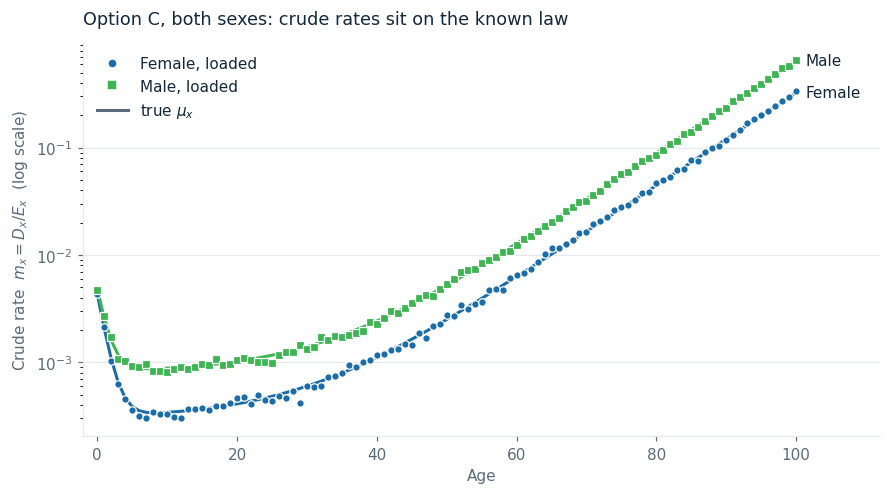

In [11]:
std = L.standard_table(c)
p = tmp / "standard.csv"; std.to_csv(p, index=False)
back = L.load_data(p)
pd.testing.assert_frame_equal(back[COLS], c[COLS], check_exact=False, rtol=1e-12)
print("read back:", back.shape, back.attrs["view"], back.attrs["year"])

fig, ax = plt.subplots(figsize=(8.2, 4.6), dpi=110)
for sex, color, marker in (("Female", BLUE, "o"), ("Male", GREEN, "s")):
    part, t = c[c["sex"] == sex], truth[(sex, 2020)]
    ax.plot(t["age"], t["mu_true"], color=color, lw=2, zorder=2)
    ax.scatter(part["age"], part["mx_raw"], s=24, marker=marker, color=color, edgecolor="white", linewidth=0.8, zorder=3)
    ax.annotate(sex, (100, t["mu_true"].iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK, fontsize=10, va="center")
ax.set_yscale("log"); ax.set_xlim(-2, 112)
ax.set_xlabel("Age", color=INK_SOFT); ax.set_ylabel("Crude rate  $m_x = D_x / E_x$  (log scale)", color=INK_SOFT)
ax.set_title("Option C, both sexes: crude rates sit on the known law", loc="left", color=INK, fontsize=11.5, pad=12)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color(GRID)
ax.tick_params(colors=INK_SOFT)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, mec="white", label="Female, loaded"),
                   Line2D([], [], marker="s", ls="", color=GREEN, mec="white", label="Male, loaded"),
                   Line2D([], [], color=INK_SOFT, lw=2, label="true $\\mu_x$")], loc="upper left", frameon=False, labelcolor=INK)
fig.tight_layout(); plt.show()

## 9. The real France HMD files (optional)

Directly usable in `HMDB/`: **`FRATNP_Mx_1x1.txt` + `FRA_Exposures_1x1.txt`** - HMD's own processed outputs (Option A).
`FRATNPdeath.txt` is the InputDB (refused); the `*ltper` files are life tables whose rates are closed at the oldest ages by HMD's
model, so not crude. The cell writes the standard file with both sexes to `sample_data/`.

In [12]:
import os
POST3 = Path(os.environ.get("MORTALITY_POST3_DIR",
             "."))
E, M = POST3 / "HMDB" / "FRA_Exposures_1x1.txt", POST3 / "HMDB" / "FRATNP_Mx_1x1.txt"

if E.exists() and M.exists():
    info = L.inspect_file(E)
    print(f"{info.name}: {info.origin}, views {info.views}, years {info.years[0]}-{info.years[-1]}, sexes {info.sexes}")
    fr = L.load_separate(exposure=E, rates=M, year=2020)
    display(L.qc_summary(fr))
    out = ROOT / "sample_data" / "FRA_taux_bruts_moment_2020_female_male.csv"
    L.standard_table(fr).to_csv(out, index=False)
    print("written:", out.relative_to(ROOT), "-", len(fr), "rows, both sexes")
else:
    print("France HMD files not found - section skipped.")

FRA_Exposures_1x1.txt: HMD, views ['period'], years 1816-2024, sexes ['Female', 'Male']


,Contrôle,Female,Male
0,Plage d'âge,0 - 109,0 - 109
1,Nombre de lignes,110,110
2,Nb Dx = 0,0,0
3,Valeurs manquantes (exclues),0,0
4,Décès totaux (somme des Dx),"327,279","327,305"


written: sample_data\FRA_taux_bruts_moment_2020_female_male.csv - 220 rows, both sexes
